In [35]:
import pandas as pd

# Direct raw URL provided by Entry Elevate
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"

# Load data directly from URL into Pandas
df = pd.read_csv(url)

# Display dataset summary & preview top rows
print("Data successfully loaded from GitHub!")
print("\n--- FIRST 5 ROWS ---")
print(df.head())

print("\n--- DATASET SUMMARY ---")
print(df.info())

Data successfully loaded from GitHub!

--- FIRST 5 ROWS ---
   Campaign_ID              Company Campaign_Type Target_Audience Duration  \
0            1             TechCorp         Email     Women 25-34  30 days   
1            2  Innovate Industries    Influencer     Women 35-44  45 days   
2            3       NexGen Systems  Social Media     Women 25-34  45 days   
3            4  Innovate Industries         Email     Women 25-34  45 days   
4            5  Data Tech Solutions    Influencer       Men 25-34  30 days   

  Channel_Used  Conversion_Rate  Acquisition_Cost     ROI          Location  \
0     Facebook         5.294194              9344   62.94           Houston   
1   Google Ads         3.326375              8783   10.67  Washington, D.C.   
2    Instagram         4.056375              9111   73.20             Miami   
3    Instagram         4.496375              7420   60.92           Seattle   
4   Google Ads         4.405930              2146  138.82           Chicago 

In [36]:
import pandas as pd

# 1. Define 'df' by loading the dataset
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)

# 2. Now you can safely inspect 'df'
print("--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n--- DATA TYPES & NON-NULL COUNTS ---")
print(df.info())

--- DATASET SHAPE ---
Rows: 22029, Columns: 16

--- DATA TYPES & NON-NULL COUNTS ---
<class 'pandas.DataFrame'>
RangeIndex: 22029 entries, 0 to 22028
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Campaign_ID       22029 non-null  int64  
 1   Company           22029 non-null  str    
 2   Campaign_Type     22029 non-null  str    
 3   Target_Audience   22029 non-null  str    
 4   Duration          22029 non-null  str    
 5   Channel_Used      22029 non-null  str    
 6   Conversion_Rate   22029 non-null  float64
 7   Acquisition_Cost  22029 non-null  int64  
 8   ROI               22029 non-null  float64
 9   Location          22029 non-null  str    
 10  Language          22029 non-null  str    
 11  Clicks            22029 non-null  int64  
 12  Impressions       22029 non-null  int64  
 13  Engagement_Score  22029 non-null  int64  
 14  Customer_Segment  22029 non-null  str    
 15  Date         

In [37]:
# 1. Preview the first 5 rows
print("--- FIRST 5 ROWS ---")
print(df.head())

# 2. Dataset dimensions (Rows, Columns)
print("\n--- DATASET SHAPE ---")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

# 3. Column Names & Data Types
print("\n--- DATA TYPES & NON-NULL COUNTS ---")
print(df.info())

# 4. Check for Missing (Null) Values per Column
print("\n--- MISSING VALUES ---")
print(df.isnull().sum())

# 5. Check for Duplicate Rows
print("\n--- DUPLICATE ROWS ---")
print(f"Duplicate count: {df.duplicated().sum()}")

--- FIRST 5 ROWS ---
   Campaign_ID              Company Campaign_Type Target_Audience Duration  \
0            1             TechCorp         Email     Women 25-34  30 days   
1            2  Innovate Industries    Influencer     Women 35-44  45 days   
2            3       NexGen Systems  Social Media     Women 25-34  45 days   
3            4  Innovate Industries         Email     Women 25-34  45 days   
4            5  Data Tech Solutions    Influencer       Men 25-34  30 days   

  Channel_Used  Conversion_Rate  Acquisition_Cost     ROI          Location  \
0     Facebook         5.294194              9344   62.94           Houston   
1   Google Ads         3.326375              8783   10.67  Washington, D.C.   
2    Instagram         4.056375              9111   73.20             Miami   
3    Instagram         4.496375              7420   60.92           Seattle   
4   Google Ads         4.405930              2146  138.82           Chicago   

  Language  Clicks  Impressions  En

In [38]:
#strip white spaces from column headers
df.columns = df.columns.str.strip()

#handle duplicate rows if any
if df.duplicated().sum() > 0:
    df = df.drop_duplicates()
    print(f"duplicates removed.new shape: {df.shape}")
    
    #fill missing numeric values with median
    num_cols = df.select_dtypes(include=[np.number]).columns
    for col in num_cols:
        if df[col].isnull().sum() > 0:
            df[col] = df[col].fillna(df[col].median())
#fill missing categorical values with mode
cat_cols = df.select_dtypes(include=["object" , "str"]).columns
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])   
        print("Phase 1 Complete: Data cleaned and missing values resolved!")        

In [39]:
# Generate descriptive statistics for numerical columns
print("--- DESCRIPTIVE STATISTICS (NUMERICAL METRICS) ---")
print(df.describe())

--- DESCRIPTIVE STATISTICS (NUMERICAL METRICS) ---
        Campaign_ID  Conversion_Rate  Acquisition_Cost           ROI  \
count  22029.000000     22029.000000      22029.000000  22029.000000   
mean   11015.000000         4.757232       5522.740842    182.863648   
std     6359.368876         0.960393       2597.666260    301.619721   
min        1.000000         2.015723       1000.000000    -98.300000   
25%     5508.000000         4.130705       3286.000000     -4.080000   
50%    11015.000000         4.761527       5525.000000     93.650000   
75%    16522.000000         5.429335       7766.000000    247.310000   
max    22029.000000         7.469907       9999.000000   3109.790000   

             Clicks   Impressions  Engagement_Score  
count  22029.000000  22029.000000      22029.000000  
mean    2223.807572  50610.402787          6.582323  
std     1394.166380  28542.979123          1.458804  
min       30.000000   1001.000000          4.000000  
25%     1067.000000  25804.000

In [40]:
#calculate the print the number of unique campaign id values
unique_campaign_count = df["Campaign_ID"].nunique()
print(f"Number of unique Campaign_IDs: {unique_campaign_count}")

Number of unique Campaign_IDs: 22029


In [41]:
# Load dataset and convert all column names to lowercase
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.lower()

In [42]:
#unique values in the location column
unique_locations = df["location"].unique()
print(f"unique locations: {unique_locations}")

#unique values in the target_audience column as per data set
unique_segments = df["target_audience"].unique()
print(f"unique target audience segments: {unique_segments}")

unique locations: <StringArray>
[         'Houston', 'Washington, D.C.',            'Miami',
          'Seattle',          'Chicago',      'Los Angeles',
          'Atlanta',           'Dallas',         'New York',
    'San Francisco']
Length: 10, dtype: str
unique target audience segments: <StringArray>
['Women 25-34', 'Women 35-44', 'Men 25-34', 'Men 18-24', 'All Ages']
Length: 5, dtype: str


In [43]:
#count occurences of each category in campaign_type column
print("---CAMPAIGN TYPE COUNTS---")
print(df["campaign_type"].value_counts())

#count occurences of each category in Channel_Used column
print("---CHANNEL USED COUNTS---")
print(df["channel_used"].value_counts())

---CAMPAIGN TYPE COUNTS---
campaign_type
Display         4450
Search          4441
Social Media    4412
Email           4388
Influencer      4338
Name: count, dtype: int64
---CHANNEL USED COUNTS---
channel_used
Facebook      3742
Google Ads    3694
Website       3688
Instagram     3649
YouTube       3632
Email         3624
Name: count, dtype: int64


In [44]:
# Print all column names to check exact casing
print(df.columns.tolist())

['campaign_id', 'company', 'campaign_type', 'target_audience', 'duration', 'channel_used', 'conversion_rate', 'acquisition_cost', 'roi', 'location', 'language', 'clicks', 'impressions', 'engagement_score', 'customer_segment', 'date']


Available columns in df: ['Campaign_ID', 'Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Location', 'Language', 'Clicks', 'Impressions', 'Engagement_Score', 'Customer_Segment', 'Date']


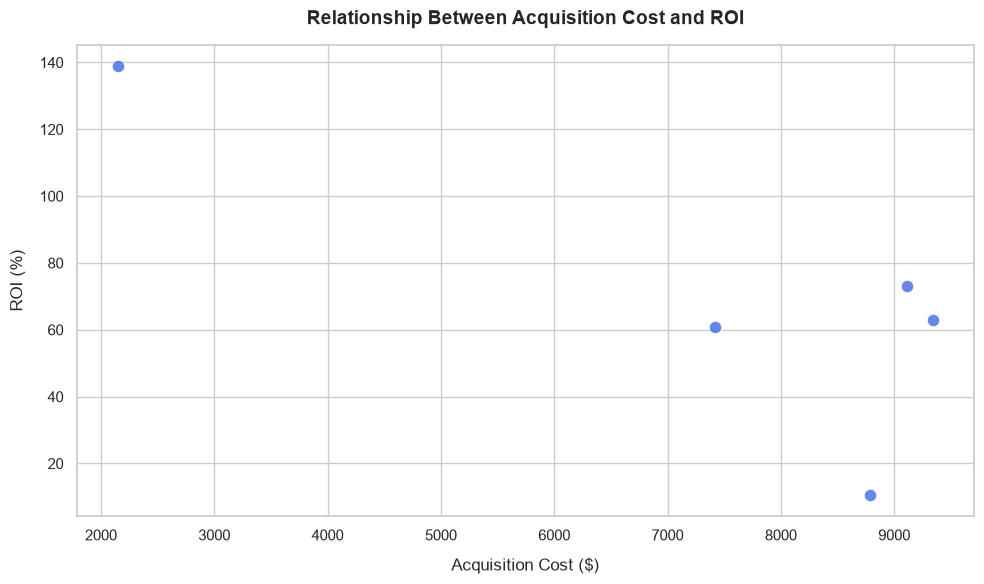

In [45]:
import io
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Re-load your dataset so 'df' is definitely defined
data_str = """Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
1,TechCorp,Email,Women 25-34,30 days,Facebook,5.294193574,9344,62.94,Houston,English,3045,67836,5,Tech Enthusiasts,01-01-2023
2,Innovate Industries,Influencer,Women 35-44,45 days,Google Ads,3.326375241,8783,10.67,"Washington, D.C.",German,1944,66361,4,Foodies,01-01-2023
3,NexGen Systems,Social Media,Women 25-34,45 days,Instagram,4.056375241,9111,73.2,Miami,Spanish,3156,86240,8,Fashionistas,01-01-2023
4,Innovate Industries,Email,Women 25-34,45 days,Instagram,4.496375241,7420,60.92,Seattle,Spanish,2388,58251,6,Foodies,01-01-2023
5,Data Tech Solutions,Influencer,Men 25-34,30 days,Google Ads,4.405929621,2146,138.82,Chicago,English,1025,34407,5,Tech Enthusiasts,01-01-2023"""

df = pd.read_csv(io.StringIO(data_str))

# 2. Print columns to verify exact names (optional check)
print("Available columns in df:", df.columns.tolist())

# 3. Set up the figure size and theme style
plt.figure(figsize=(10, 6))
sns.set_theme(style='whitegrid')

# 4. Create the scatter plot
sns.scatterplot(
    data=df,
    x='Acquisition_Cost',
    y='ROI',
    color='royalblue',
    s=80,
    alpha=0.8,
)

# 5. Add titles and axis labels
plt.title(
    'Relationship Between Acquisition Cost and ROI',
    fontsize=14,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Acquisition Cost ($)', fontsize=12, labelpad=10)
plt.ylabel('ROI (%)', fontsize=12, labelpad=10)

# 6. Render the plot
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

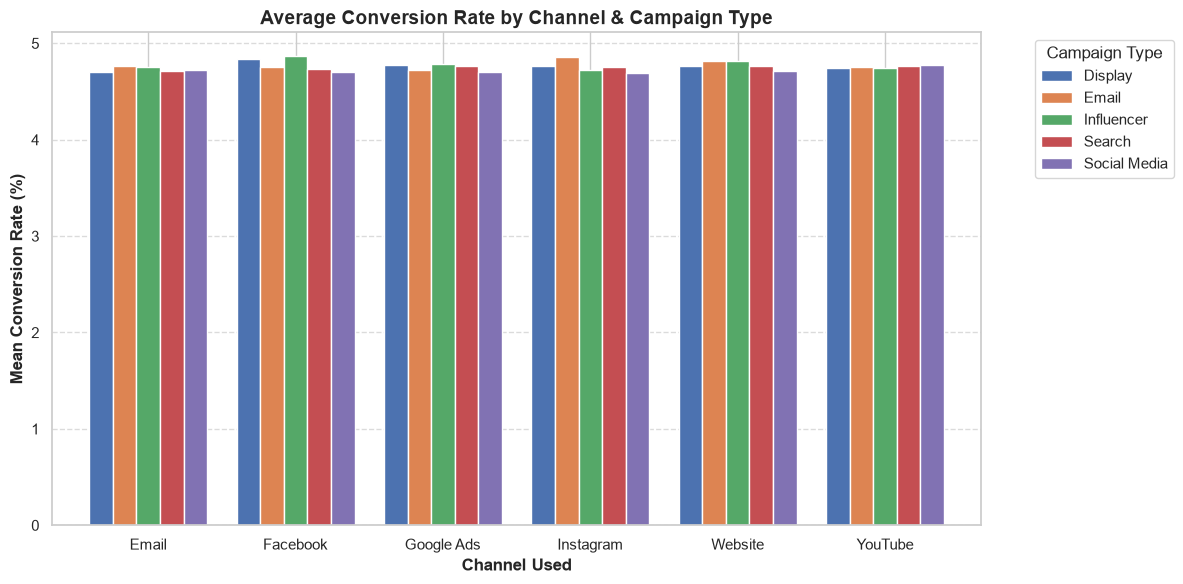

In [46]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load dataset
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)

# 2. Pivot table: Channel_Used as index, Campaign_Type as columns
pivot_df = df.pivot_table(
    index="Channel_Used",
    columns="Campaign_Type",
    values="Conversion_Rate",
    aggfunc="mean",
)

# 3. Plot grouped bar chart using Pandas
plt.figure(figsize=(12, 6))
ax = pivot_df.plot(kind="bar", figsize=(12, 6), width=0.8)

# 4. Format plot
plt.title(
    "Average Conversion Rate by Channel & Campaign Type",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Channel Used", fontsize=12, fontweight="bold")
plt.ylabel("Mean Conversion Rate (%)", fontsize=12, fontweight="bold")
plt.xticks(rotation=0)
plt.legend(title="Campaign Type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_17488\1931505317.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


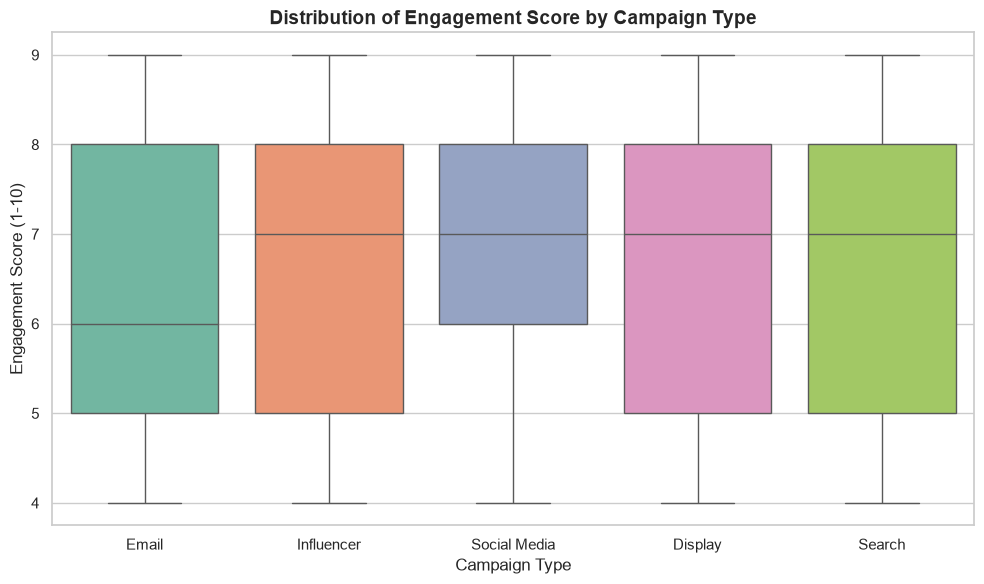

In [47]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the dataset
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)

# 2. Set figure size
plt.figure(figsize=(10, 6))

# 3. Create the simple box plot
sns.boxplot(
    data=df, x="Campaign_Type", y="Engagement_Score", palette="Set2"
)

# 4. Add titles and labels
plt.title(
    "Distribution of Engagement Score by Campaign Type",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Campaign Type", fontsize=12)
plt.ylabel("Engagement Score (1-10)", fontsize=12)

# 5. Display the plot
plt.tight_layout()
plt.show()

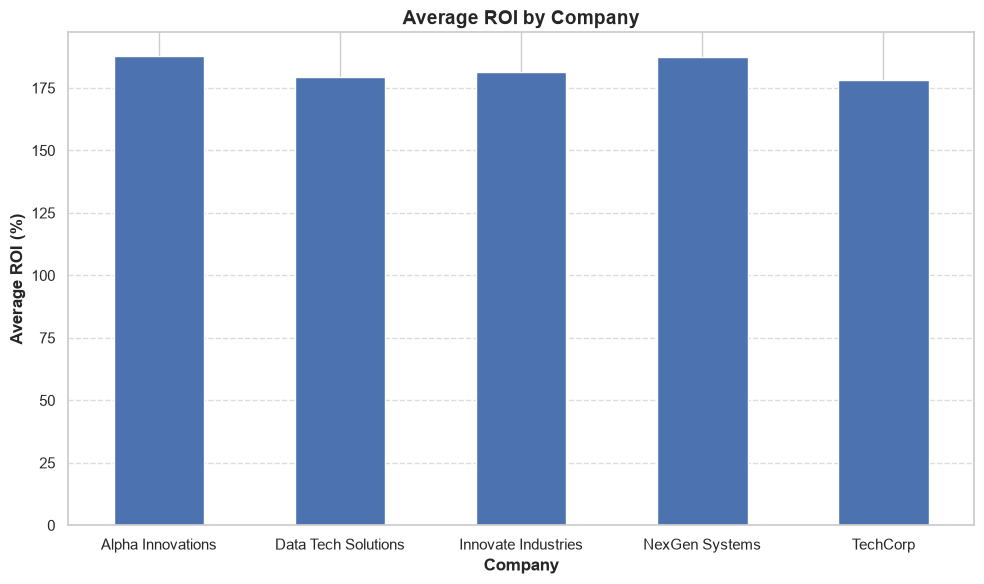

In [48]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)

# Calculate mean ROI by Company
roi_by_company = df.groupby("Company")["ROI"].mean().reset_index()

# Plot using Pandas
ax = roi_by_company.plot(
    kind="bar", x="Company", y="ROI", figsize=(10, 6), legend=False
)

plt.title(
    "Average ROI by Company", fontsize=14, fontweight="bold"
)
plt.xlabel("Company", fontsize=12, fontweight="bold")
plt.ylabel("Average ROI (%)", fontsize=12, fontweight="bold")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [49]:
import pandas as pd

# Load dataset
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)

# Calculate correlation matrix
corr_matrix = df[["Engagement_Score", "Conversion_Rate"]].corr()

# Round to 2 decimal places and display directly
round(corr_matrix, 2)

,Engagement_Score,Conversion_Rate
Engagement_Score,1.00,0.01
Conversion_Rate,0.01,1.00


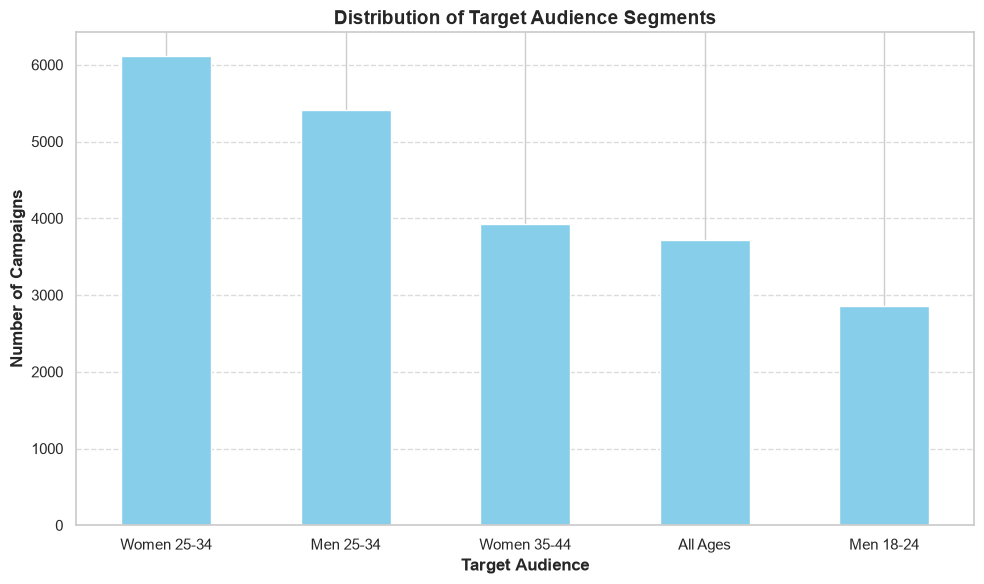

In [50]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)

# Count frequency of each Target_Audience
audience_counts = df["Target_Audience"].value_counts()

# Plot using Pandas
ax = audience_counts.plot(kind="bar", figsize=(10, 6), color="skyblue")

plt.title(
    "Distribution of Target Audience Segments", fontsize=14, fontweight="bold"
)
plt.xlabel("Target Audience", fontsize=12, fontweight="bold")
plt.ylabel("Number of Campaigns", fontsize=12, fontweight="bold")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [51]:
print(df.columns.tolist())

['Campaign_ID', 'Company', 'Campaign_Type', 'Target_Audience', 'Duration', 'Channel_Used', 'Conversion_Rate', 'Acquisition_Cost', 'ROI', 'Location', 'Language', 'Clicks', 'Impressions', 'Engagement_Score', 'Customer_Segment', 'Date']


Highest Conversion Rate Segment per Language:
   Language   Customer_Segment  Conversion_Rate
0   English   Tech Enthusiasts         5.022731
1    French  Health & Wellness         4.689704
2    German            Foodies         4.705430
3  Mandarin  Health & Wellness         4.756125
4   Spanish            Foodies         4.663610


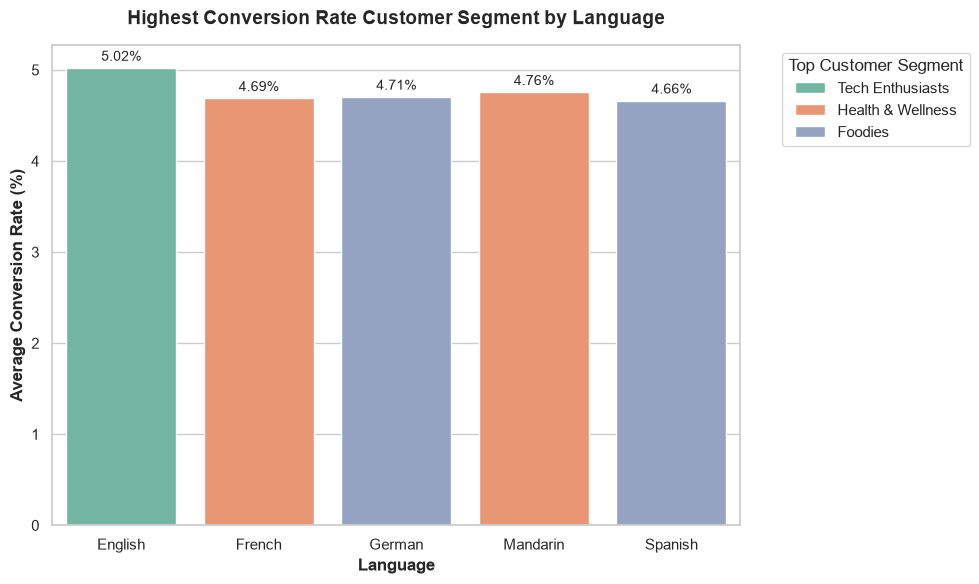

In [52]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load your dataset
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)

# 2. Strip leading/trailing whitespaces from column names
df.columns = df.columns.str.strip()

# 3. Calculate mean Conversion_Rate per Language and Customer_Segment
avg_conv = (
    df.groupby(["Language", "Customer_Segment"])["Conversion_Rate"]
    .mean()
    .reset_index()
)

# 4. Get the highest performing Customer_Segment for each Language
top_segments = (
    avg_conv.sort_values("Conversion_Rate", ascending=False)
    .groupby("Language")
    .first()
    .reset_index()
)

print("Highest Conversion Rate Segment per Language:")
print(top_segments)

# 5. Plot the simple bar chart
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

ax = sns.barplot(
    data=top_segments,
    x="Language",
    y="Conversion_Rate",
    hue="Customer_Segment",
    palette="Set2",
)

# Add numeric value labels to bars
for p in ax.patches:
    height = p.get_height()
    if not pd.isna(height) and height > 0:
        ax.annotate(
            f"{height:.2f}%",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=10,
            xytext=(0, 3),
            textcoords="offset points",
        )

plt.title(
    "Highest Conversion Rate Customer Segment by Language",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Language", fontsize=12, fontweight="bold")
plt.ylabel("Average Conversion Rate (%)", fontsize=12, fontweight="bold")
plt.legend(title="Top Customer Segment", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

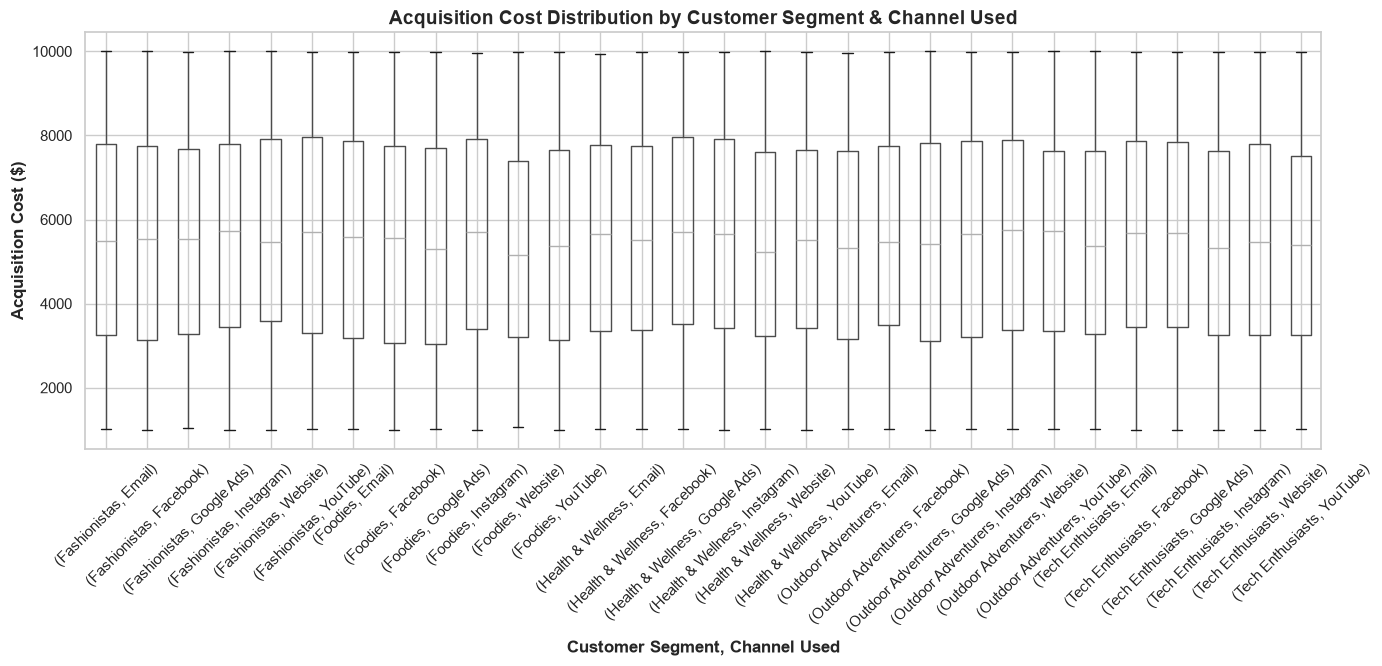

In [53]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.strip()

# Create boxplot grouped by Customer_Segment and Channel_Used using pandas
df.boxplot(
    column="Acquisition_Cost",
    by=["Customer_Segment", "Channel_Used"],
    figsize=(14, 7),
    rot=45,
)

plt.title(
    "Acquisition Cost Distribution by Customer Segment & Channel Used",
    fontsize=14,
    fontweight="bold",
)
plt.suptitle("")  # Clear automatic default title
plt.xlabel("Customer Segment, Channel Used", fontsize=12, fontweight="bold")
plt.ylabel("Acquisition Cost ($)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

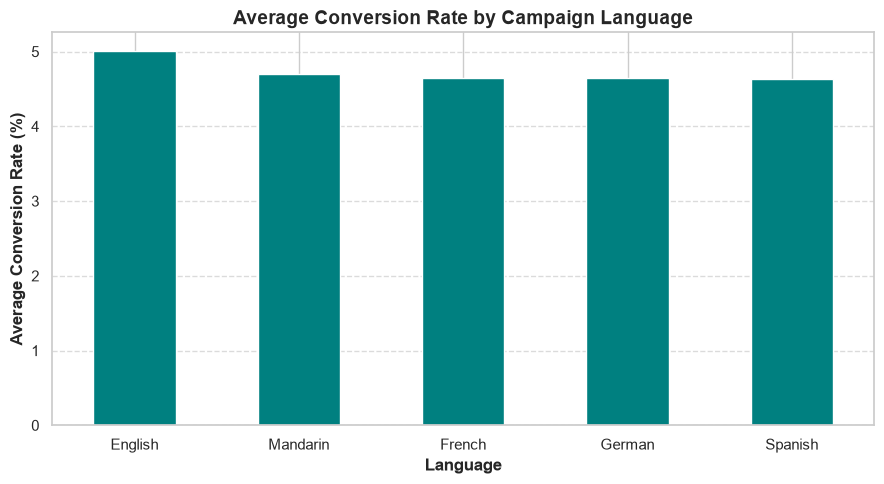

In [54]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset & clean column names
df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Calculate mean Conversion_Rate by Language
lang_conv = df.groupby("Language")["Conversion_Rate"].mean().sort_values(ascending=False)

# Plot using Pandas
ax = lang_conv.plot(kind="bar", figsize=(9, 5), color="teal")

plt.title(
    "Average Conversion Rate by Campaign Language",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Language", fontsize=12, fontweight="bold")
plt.ylabel("Average Conversion Rate (%)", fontsize=12, fontweight="bold")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

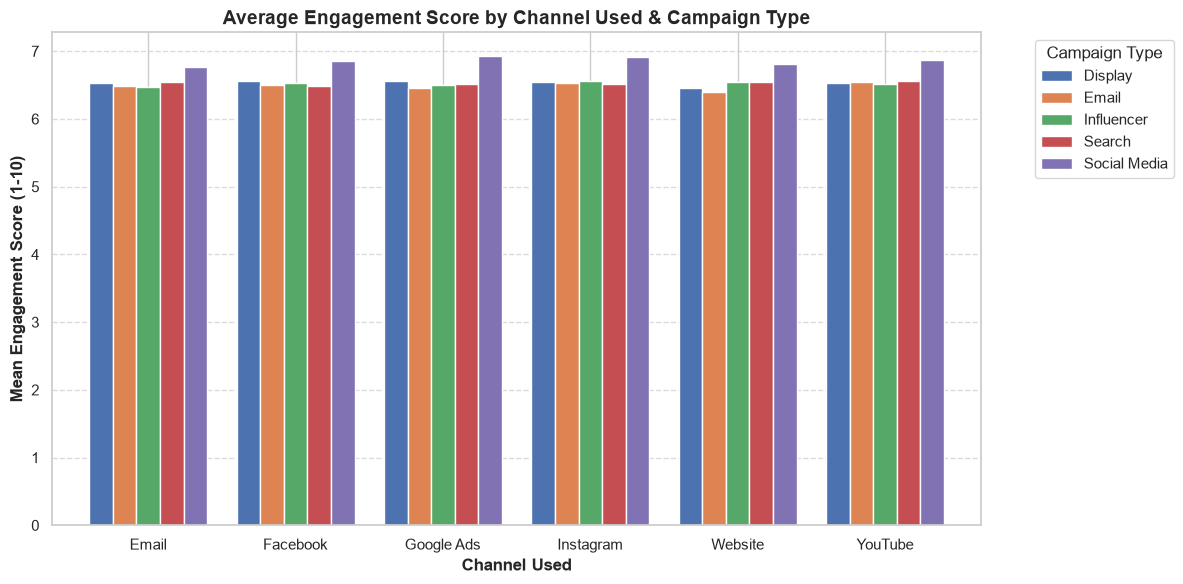

In [55]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset & clean column names
df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Create pivot table of mean Engagement_Score
pivot_df = df.pivot_table(
    index="Channel_Used",
    columns="Campaign_Type",
    values="Engagement_Score",
    aggfunc="mean",
)

# Plot grouped bar chart
ax = pivot_df.plot(kind="bar", figsize=(12, 6), width=0.8)

plt.title(
    "Average Engagement Score by Channel Used & Campaign Type",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Channel Used", fontsize=12, fontweight="bold")
plt.ylabel("Mean Engagement Score (1-10)", fontsize=12, fontweight="bold")
plt.xticks(rotation=0)
plt.legend(title="Campaign Type", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

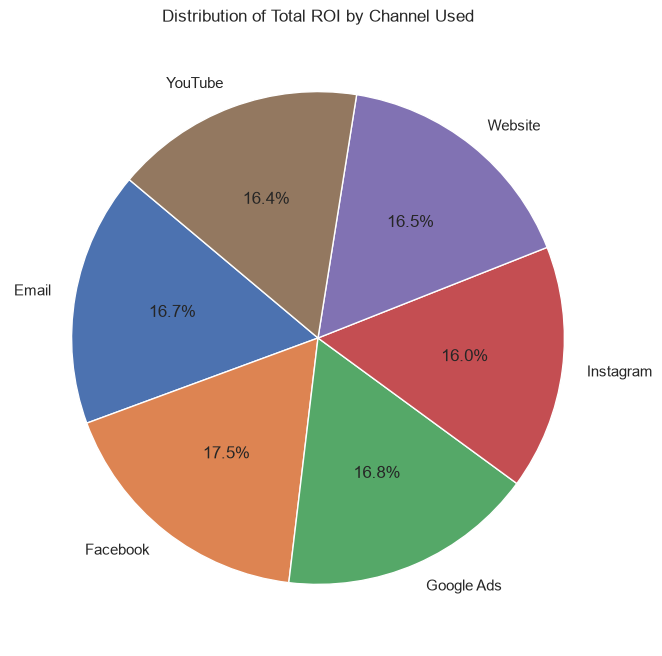

In [56]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Calculate sum of ROI by channel and plot pie chart directly
df.groupby("Channel_Used")["ROI"].sum().plot(
    kind="pie",
    figsize=(8, 8),
    autopct="%1.1f%%",
    startangle=140,
    ylabel="",  # Hide the default 'ROI' y-label for clean output
    title="Distribution of Total ROI by Channel Used",
)

plt.show()

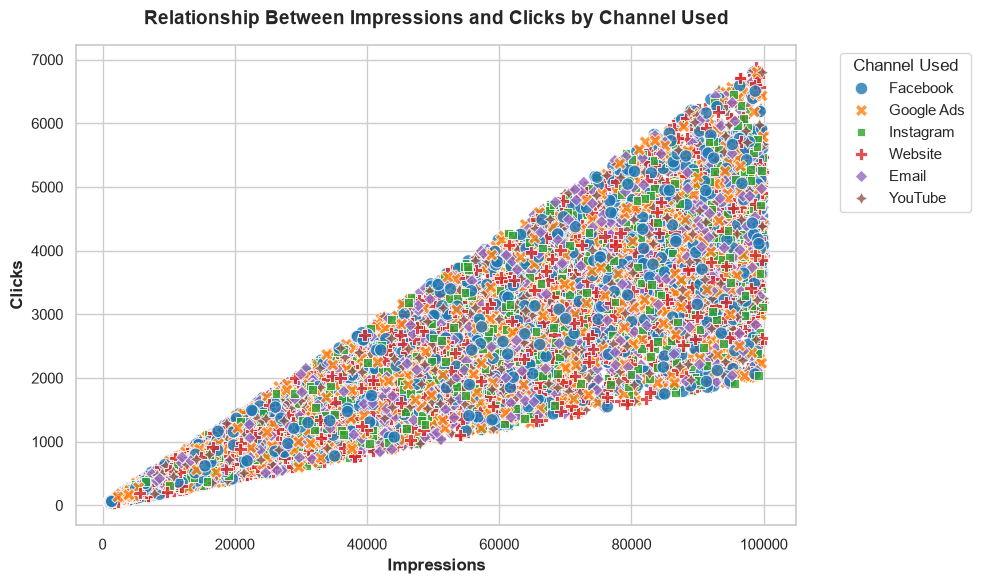

In [57]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load dataset & clean column names
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.strip()

# 2. Set figure size and grid style
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Create Scatter Plot
sns.scatterplot(
    data=df,
    x="Impressions",
    y="Clicks",
    hue="Channel_Used",
    style="Channel_Used",
    s=80,  # Marker size
    palette="tab10",
    alpha=0.8,
)

# 4. Format Titles and Axis Labels
plt.title(
    "Relationship Between Impressions and Clicks by Channel Used",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Impressions", fontsize=12, fontweight="bold")
plt.ylabel("Clicks", fontsize=12, fontweight="bold")
plt.legend(title="Channel Used", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()

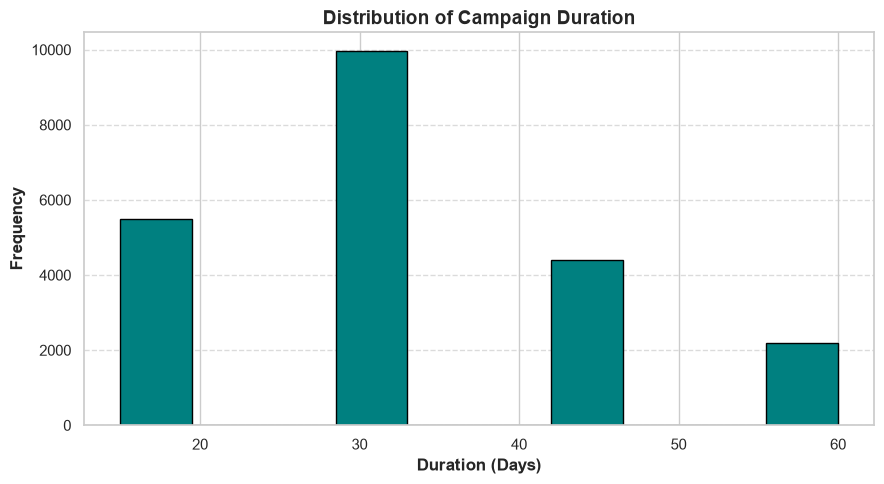

In [58]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset & clean column names
df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Convert Duration to numeric explicitly
df["Duration"] = pd.to_numeric(
    df["Duration"].astype(str).str.extract(r"(\d+)")[0], errors="coerce"
)

# Plot histogram using Pandas
ax = df["Duration"].plot(
    kind="hist", bins=10, figsize=(9, 5), color="teal", edgecolor="black"
)

plt.title("Distribution of Campaign Duration", fontsize=14, fontweight="bold")
plt.xlabel("Duration (Days)", fontsize=12, fontweight="bold")
plt.ylabel("Frequency", fontsize=12, fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

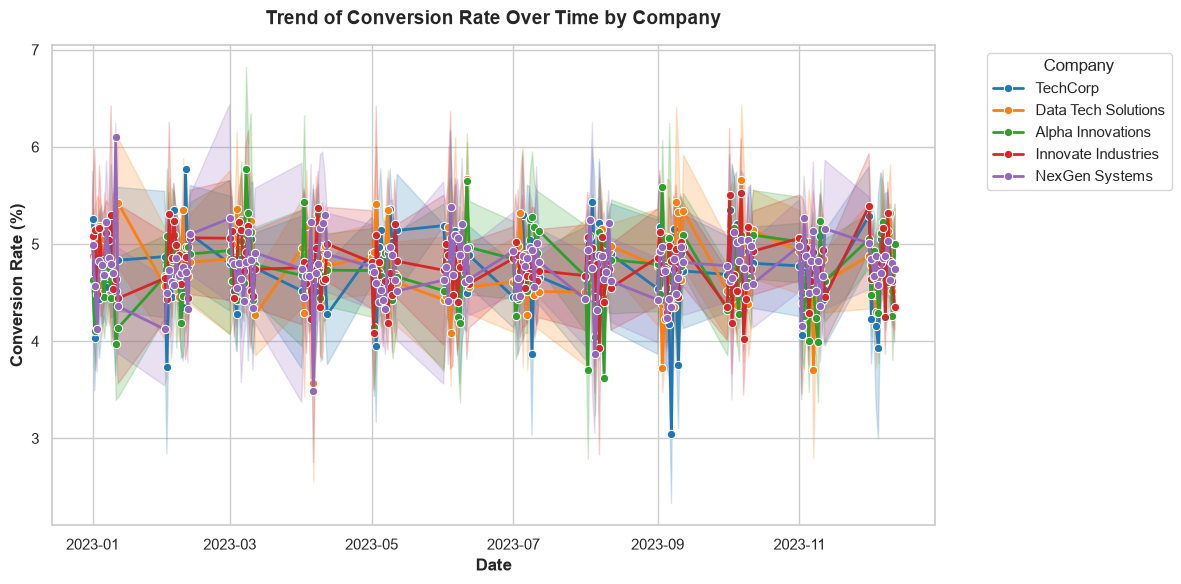

In [59]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load dataset & clean column names
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.strip()

# 2. Convert Date to datetime format for proper chronological sorting
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df = df.sort_values("Date")

# 3. Set figure size and style
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# 4. Create Line Plot
sns.lineplot(
    data=df,
    x="Date",
    y="Conversion_Rate",
    hue="Company",
    marker="o",
    linewidth=2,
    palette="tab10",
)

# 5. Format Titles and Axis Labels
plt.title(
    "Trend of Conversion Rate Over Time by Company",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Conversion Rate (%)", fontsize=12, fontweight="bold")
plt.legend(title="Company", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()

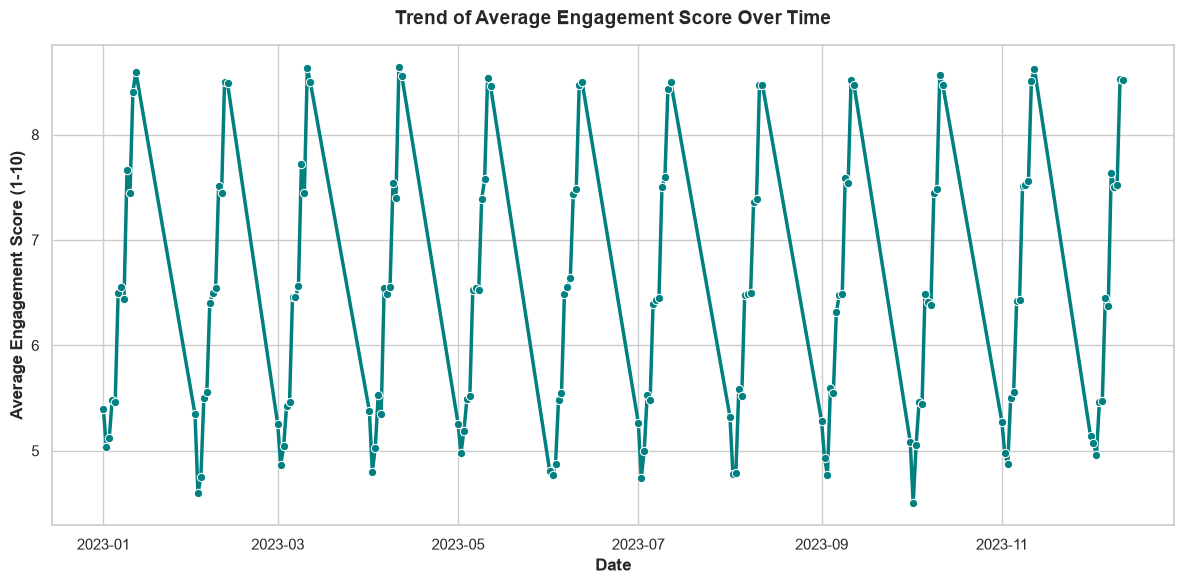

In [60]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load dataset & clean column names
url = "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
df = pd.read_csv(url)
df.columns = df.columns.str.strip()

# 2. Convert Date to datetime and calculate average daily Engagement Score
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
daily_engagement = (
    df.groupby("Date")["Engagement_Score"].mean().reset_index().sort_values("Date")
)

# 3. Set figure size and style
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# 4. Create Line Plot
sns.lineplot(
    data=daily_engagement,
    x="Date",
    y="Engagement_Score",
    marker="o",
    color="teal",
    linewidth=2.5,
)

# 5. Format Titles and Axis Labels
plt.title(
    "Trend of Average Engagement Score Over Time",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Date", fontsize=12, fontweight="bold")
plt.ylabel("Average Engagement Score (1-10)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

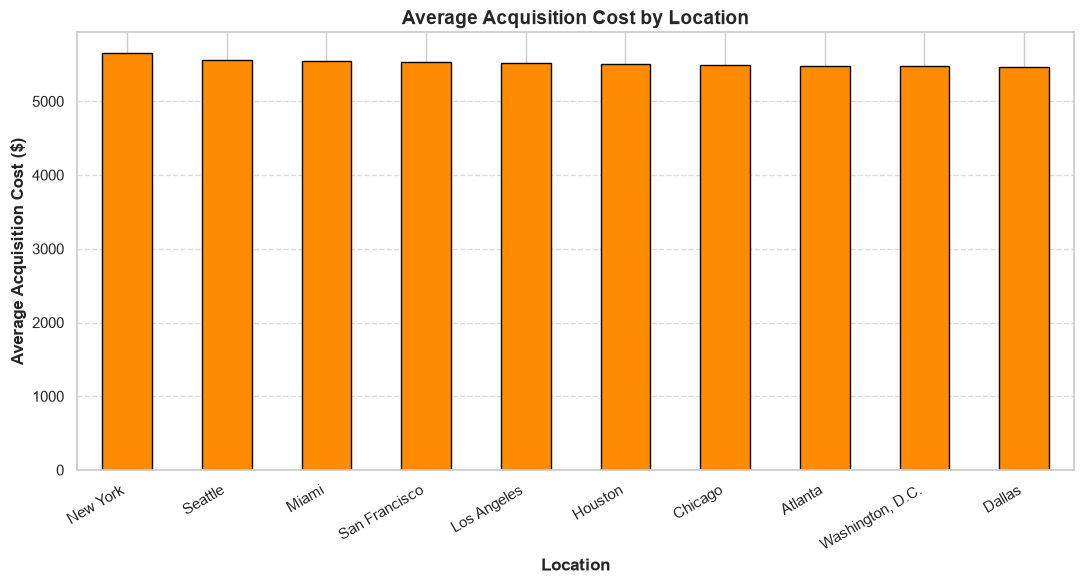

In [61]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset & clean column names
df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Calculate mean Acquisition Cost by Location and sort
loc_cost = df.groupby("Location")["Acquisition_Cost"].mean().sort_values(ascending=False)

# Plot using Pandas
ax = loc_cost.plot(
    kind="bar", figsize=(11, 6), color="darkorange", edgecolor="black"
)

plt.title("Average Acquisition Cost by Location", fontsize=14, fontweight="bold")
plt.xlabel("Location", fontsize=12, fontweight="bold")
plt.ylabel("Average Acquisition Cost ($)", fontsize=12, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

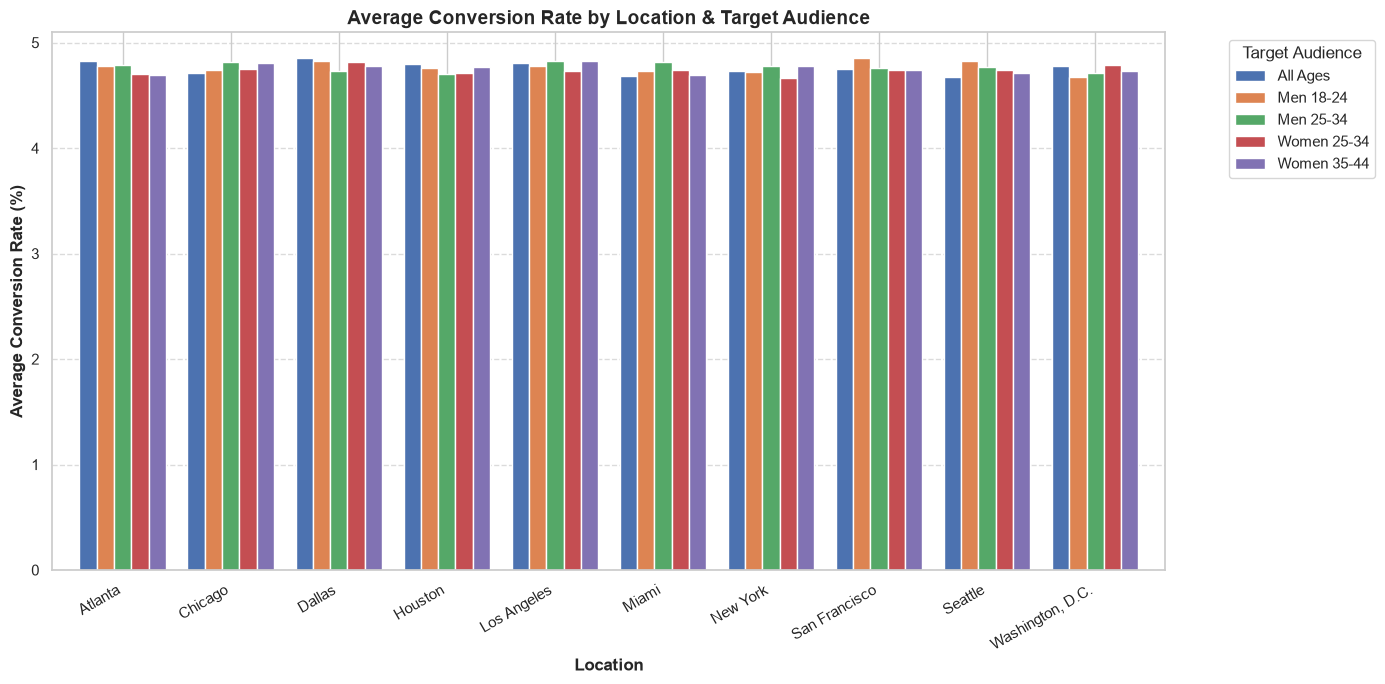

In [62]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset & clean column names
df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Create pivot table for mean Conversion_Rate
pivot_df = df.pivot_table(
    index="Location",
    columns="Target_Audience",
    values="Conversion_Rate",
    aggfunc="mean",
)

# Plot grouped bar chart using Pandas
ax = pivot_df.plot(kind="bar", figsize=(14, 7), width=0.8)

plt.title(
    "Average Conversion Rate by Location & Target Audience",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Location", fontsize=12, fontweight="bold")
plt.ylabel("Average Conversion Rate (%)", fontsize=12, fontweight="bold")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Target Audience", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

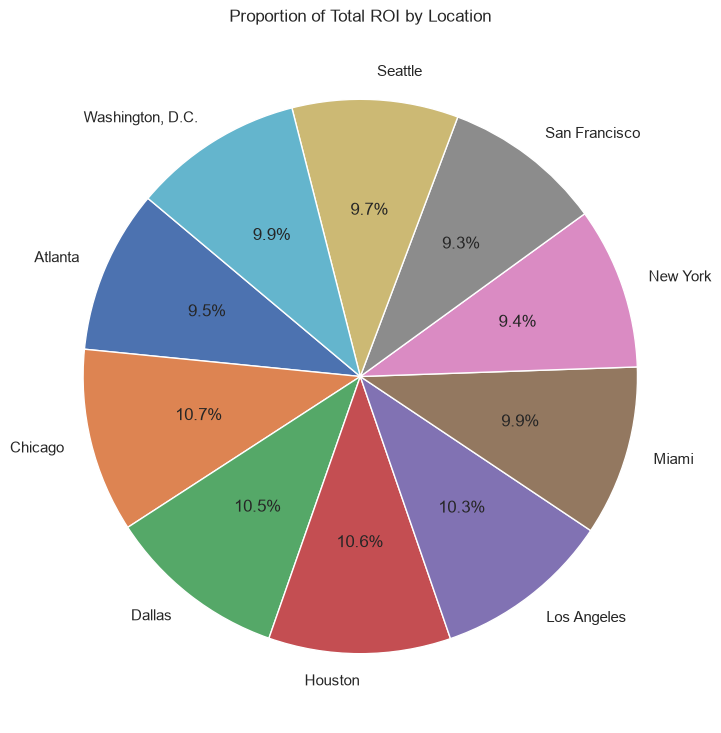

In [63]:
import matplotlib.pyplot as plt
import pandas as pd

# Load dataset & clean column names
df = pd.read_csv(
    "https://raw.githubusercontent.com/ArchanaInsights/Datasets/main/marketing_campaign.csv"
)
df.columns = df.columns.str.strip()

# Calculate sum of ROI by Location and plot pie chart directly
df.groupby("Location")["ROI"].sum().plot(
    kind="pie",
    figsize=(9, 9),
    autopct="%1.1f%%",
    startangle=140,
    ylabel="",  # Hide default y-label
    title="Proportion of Total ROI by Location",
)

plt.show()